In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
from pathlib import Path

In [3]:
import os, sys, importlib
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(parent_dir)
print(parent_dir)

c:\Users\Admin\Documents\msc_project\Image-processing-strategies


In [4]:
import monkey_tools.extract_metric
importlib.reload(monkey_tools.extract_metric)

from monkey_tools.extract_metric import cnr_wm_gm # re-import updated function

#  <span style="color:#C133FF"> *After MC acquisition, comparing fieldmaps with and without acdc shimming using our 15ch MC* </span> 

To get the CSVs that we are opening on the following cells you can run:

''
sct_extrat_metric -i input.nii.gz -f sc_msk.nii.gz -method bin -perslice 1 -o input_slicewise_metrics.csv
''

Participant id connection: </br>
chi_026 -> sub01 </br>
chi_030 -> sub02 </br>
chi_032 -> sub03 </br>
chi_033 -> sub04 (Note that chi_034 is the retest and siemens acquisition for the same participant) </br>
chi_035 -> sub05 </br>
chi_036 -> sub06 </br>
chi_037 -> sub07 </br>
chi_038 -> sub08 </br>

In [13]:
import importlib
import multicoil_paths as data_paths

importlib.reload(data_paths)  # Refresh after saving path edits
participants = data_paths.participants

##  <span style="color:#12B06C"> Figure 2: Effect of MC shimming across participants

The purpose of Figure 2 is to evaluate whether MC shimming improves $B_0$ homogeneity relative to baseline across participants.

**Panel A — Slicewise field distribution**

$$
\mu_{\Delta B_0}(z) \pm \sigma_{\Delta B_0}(z)
$$

Slicewise mean $\Delta B_0$ and spatial standard deviation within the spinal cord mask, showing how the field distribution changes along the inferior–superior direction after MC shimming.

**Panel B — Whole-cord field error**

$$
\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^{N}\left(\Delta B_{0,i}\right)^2
$$

Whole-cord MSE before and after MC shimming, providing a global measure of residual $B_0$ error relative to the target field ($\Delta B_0 = 0$ Hz).

###  <span style="color:#12B06C"> Figure 2 panel slicewise B0 S->I</span> 
Load csvs and create figure 2 panel b



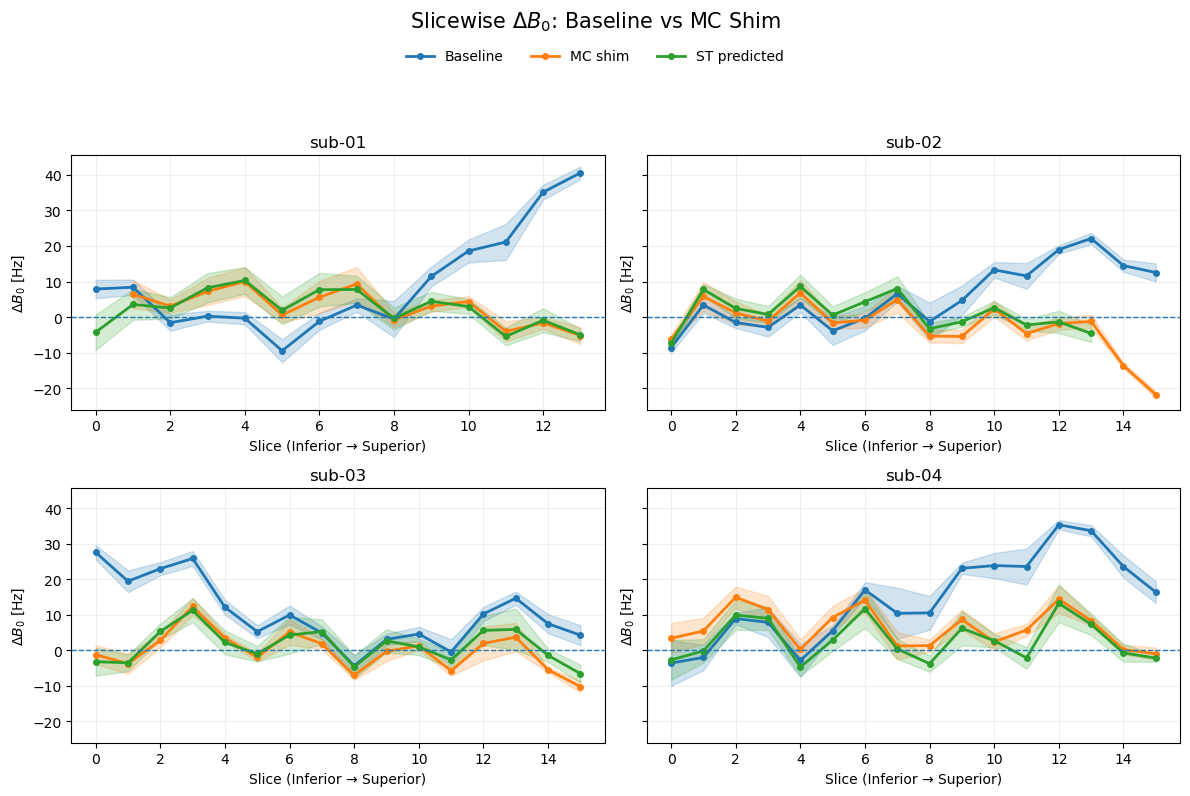

In [10]:
mean_col = "BIN()"
std_col = "STD()"
slice_col = "Slice (I->S)"

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharey=True
)

axes = axes.flatten()

for ax, (participant_ID, participant_data) in zip(axes, data.items()):

    baseline = participant_data["baseline"]
    shimmed = participant_data["shimmed"]
    predicted = participant_data["predicted"]

    # -----------------------
    # Baseline
    # -----------------------
    x = baseline[slice_col]
    mean = baseline[mean_col]
    std = baseline[std_col]

    line = ax.plot(
        x, mean,
        linewidth=2,
        marker="o",
        markersize=4,
        label="Baseline"
    )

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.20,
        color=line[0].get_color()
    )

    # -----------------------
    # MC shim
    # -----------------------
    x = shimmed[slice_col]
    mean = shimmed[mean_col]
    std = shimmed[std_col]

    line = ax.plot(
        x, mean,
        linewidth=2,
        marker="o",
        markersize=4,
        label="MC shim"
    )

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.20,
        color=line[0].get_color()
    )

    # -----------------------
    # Predicted
    # -----------------------
    x = predicted[slice_col]
    mean = predicted[mean_col]
    std = predicted[std_col]

    line = ax.plot(
        x, mean,
        linewidth=2,
        marker="o",
        markersize=4,
        label="ST predicted"
    )

    ax.fill_between(
        x,
        mean - std,
        mean + std,
        alpha=0.20,
        color=line[0].get_color()
    )

    # -----------------------
    # Formatting
    # -----------------------
    ax.axhline(0, linestyle="--", linewidth=1)

    ax.set_title(participant_ID)
    ax.set_xlabel("Slice (Inferior → Superior)")
    ax.set_ylabel(r"$\Delta B_0$ [Hz]")

    ax.grid(alpha=0.2)


# One legend for the whole figure
handles, labels = axes[0].get_legend_handles_labels()

fig.suptitle(
    r"Slicewise $\Delta B_0$: Baseline vs MC Shim",
    fontsize=15,
    y=0.99
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=3,
    frameon=False
)

# Leave room at the top for title + legend
plt.tight_layout(rect=[0, 0, 1, 0.90])

plt.show()

sub-01, sh: no metrics on slices [14, 15]; shown as gaps
sub-01, sh_acdc: no metrics on slices [0, 14, 15]; shown as gaps


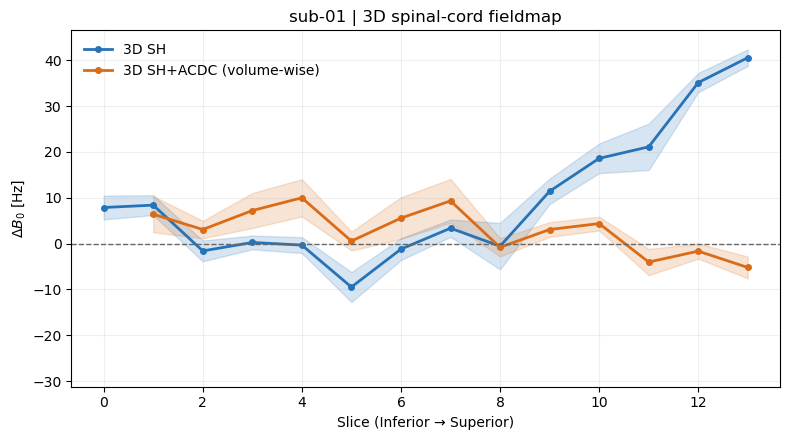

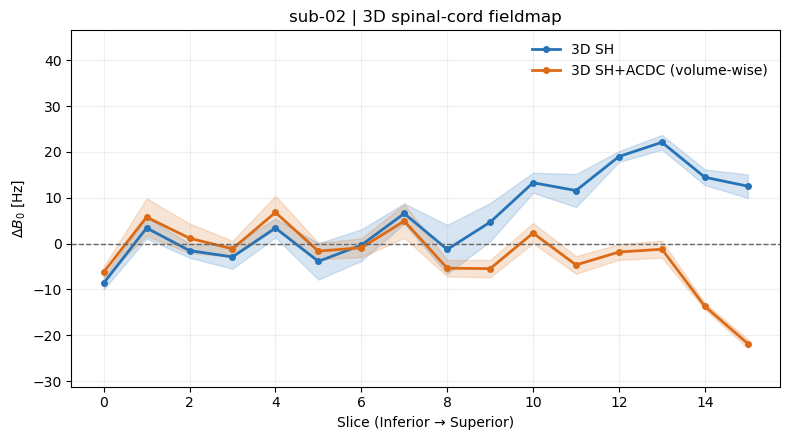

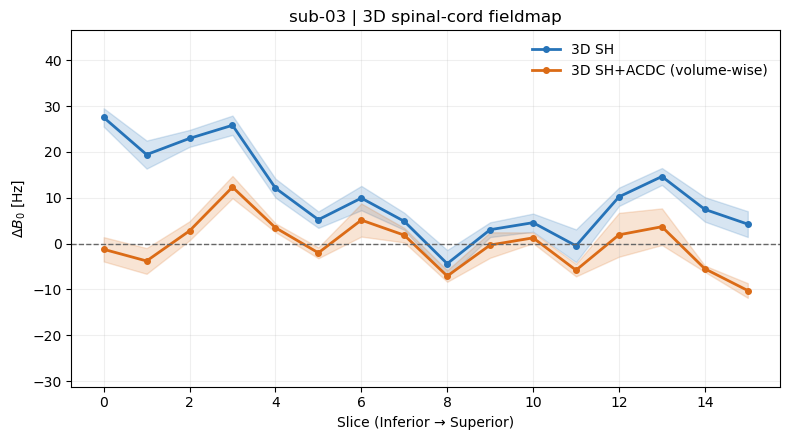

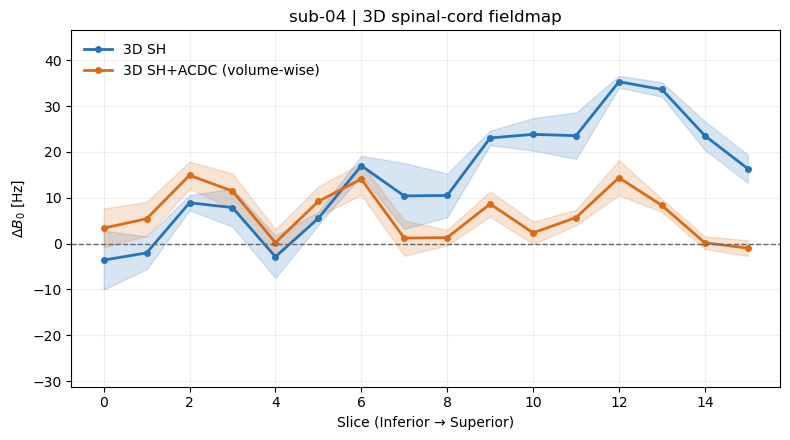

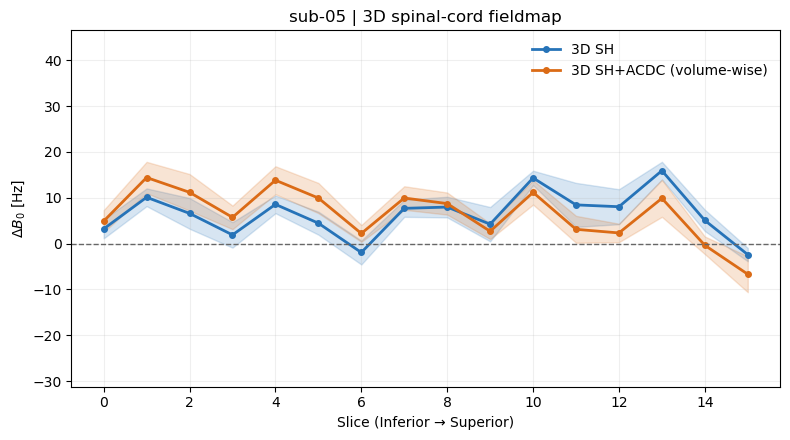

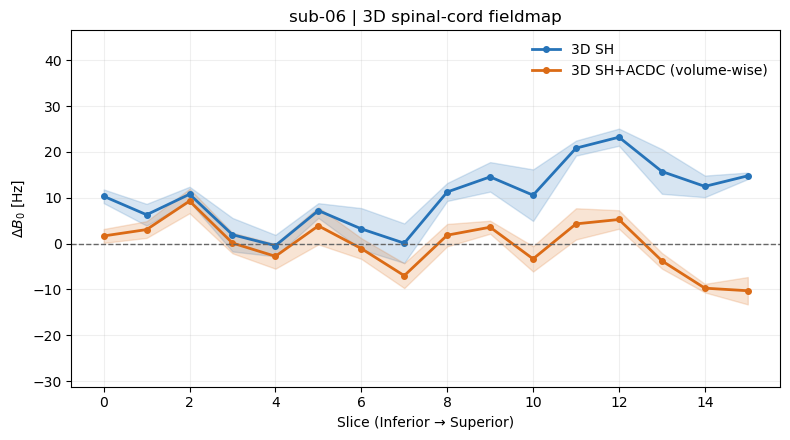

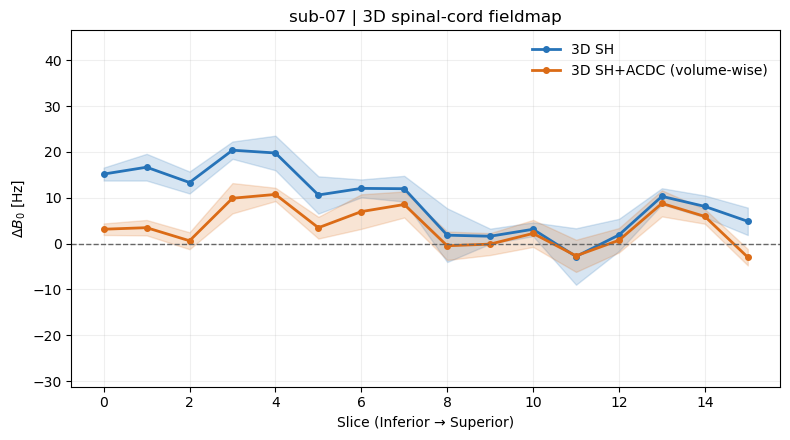

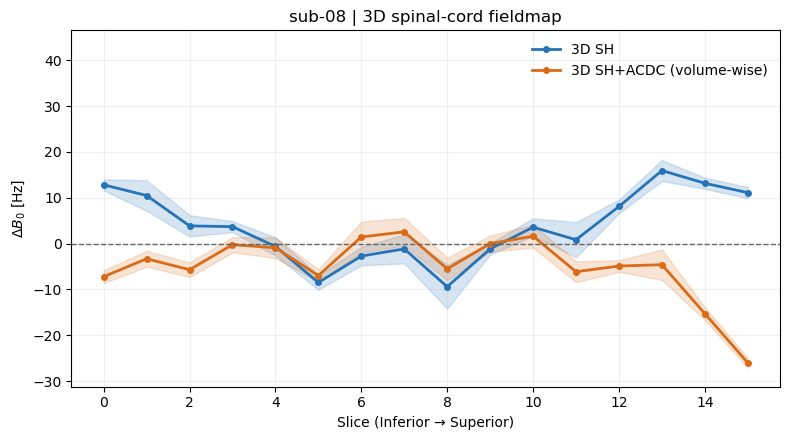

In [11]:
# Separate figures for all eight participants: measured 3D data only.
# CSVs are read here; no old path-definition or data-loading cells are needed.
styles = {
    "sh": ("3D SH", "#2673b8"),
    "sh_acdc": ("3D SH+ACDC (volume-wise)", "#db6b16"),
}
slice_col = "Slice (I->S)"
std_col = "STD()"
data_3d = {}
extents = []

for participant_id, conditions in participants.items():
    data_3d[participant_id] = {}
    for condition in styles:
        csv_path = conditions[condition]["b0_csv_path"]
        if not csv_path or not Path(csv_path).is_file():
            raise FileNotFoundError(f"{participant_id}, {condition}: {csv_path!r}")
        frame = pd.read_csv(csv_path)
        # BIN and WA agree for binary masks; preserve the CSV's actual method.
        mean_col = next((c for c in ("BIN()", "WA()") if c in frame), None)
        if mean_col is None:
            raise ValueError(f"{participant_id}, {condition}: missing BIN()/WA()")
        frame = frame[[slice_col, mean_col, std_col]].rename(
            columns={slice_col: "Slice", mean_col: "Mean", std_col: "SD"}
        ).apply(pd.to_numeric, errors="raise").sort_values("Slice")
        if frame.empty or not np.isfinite(frame["Slice"]).all():
            raise ValueError(f"{participant_id}, {condition}: empty/invalid slice indices")
        valid = np.isfinite(frame[["Mean", "SD"]]).all(axis=1)
        if not valid.any():
            raise ValueError(f"{participant_id}, {condition}: no finite metrics")
        if not valid.all():
            print(f"{participant_id}, {condition}: no metrics on slices "
                  f"{frame.loc[~valid, 'Slice'].tolist()}; shown as gaps")
            frame.loc[~valid, ["Mean", "SD"]] = np.nan
        if frame["Slice"].duplicated().any() or (frame["SD"] < 0).any():
            raise ValueError(f"{participant_id}, {condition}: invalid slice/SD values")
        data_3d[participant_id][condition] = frame
        extents.extend((float((frame.Mean-frame.SD).min()),
                        float((frame.Mean+frame.SD).max())))

# Shared vertical scale makes separate participants visually comparable.
low, high = min(0.0, min(extents)), max(0.0, max(extents))
padding = max(1.0, 0.06 * (high-low))
figures_3d = {}
for participant_id, conditions in data_3d.items():
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for condition, (label, color) in styles.items():
        frame = conditions[condition]
        x, mean, sd = (frame[c].to_numpy() for c in ("Slice", "Mean", "SD"))
        ax.plot(x, mean, color=color, marker="o", markersize=4,
                linewidth=2, label=label)
        ax.fill_between(x, mean-sd, mean+sd, color=color, alpha=0.18)
    ax.axhline(0, color="0.4", linestyle="--", linewidth=1)
    ax.set(title=f"{participant_id} | 3D spinal-cord fieldmap",
           xlabel="Slice (Inferior → Superior)", ylabel=r"$\Delta B_0$ [Hz]",
           ylim=(low-padding, high+padding))
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    fig.tight_layout()
    figures_3d[participant_id] = fig
    plt.show()


sub-01, sh: no metrics on slices [14, 15]; shown as gaps
sub-01, sh_acdc: no metrics on slices [0, 14, 15]; shown as gaps
sub-01, predicted_sh_acdc: no metrics on slices [14, 15]; shown as gaps
sub-02, predicted_sh_acdc: no metrics on slices [14, 15]; shown as gaps
sub-08, predicted_sh_acdc: no metrics on slices [0, 1, 14, 15]; shown as gaps


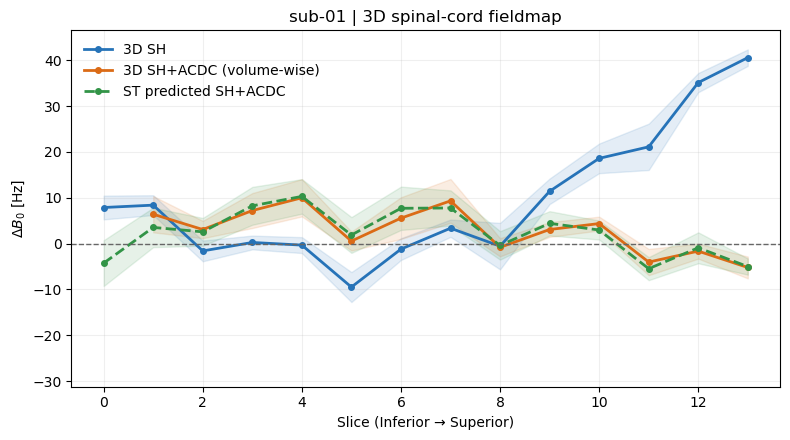

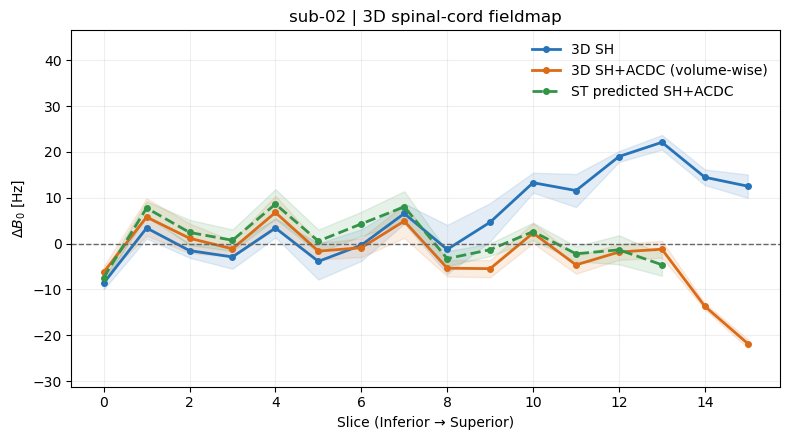

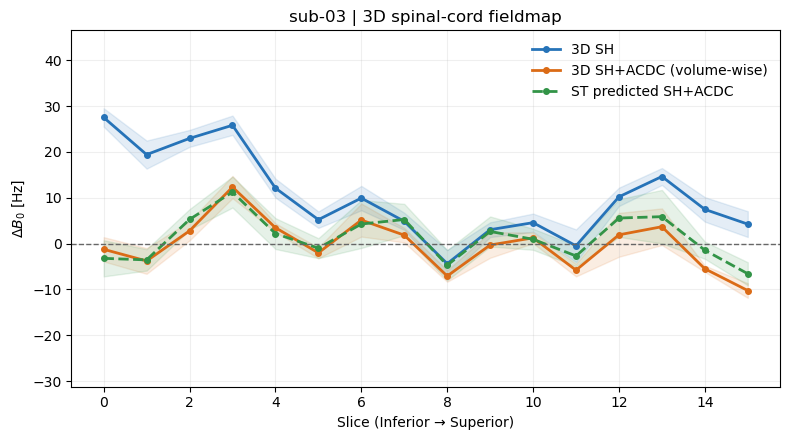

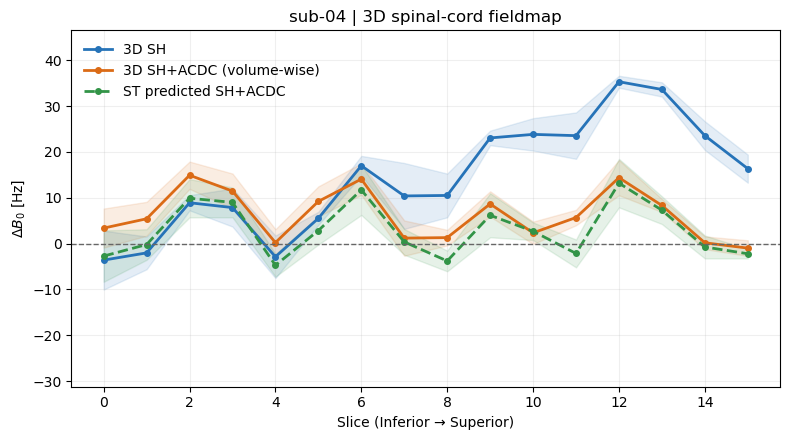

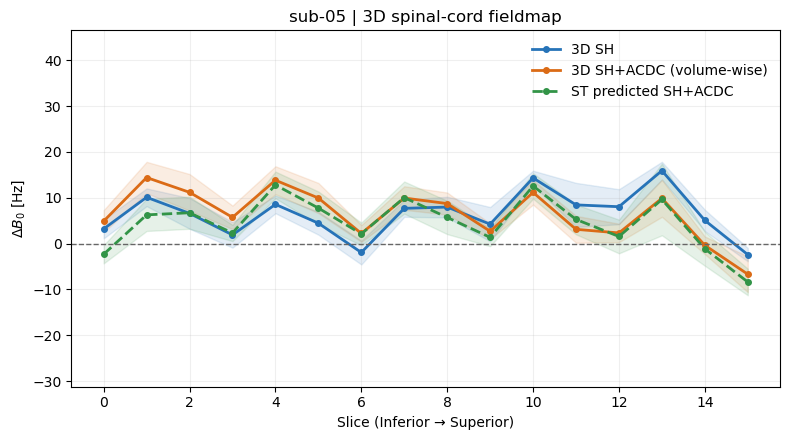

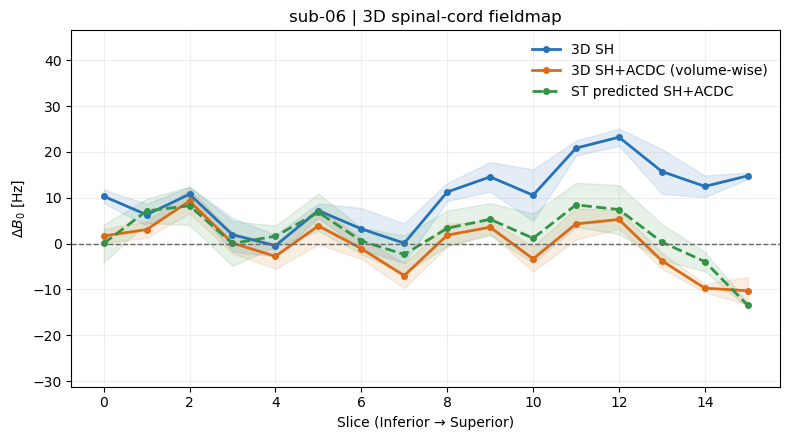

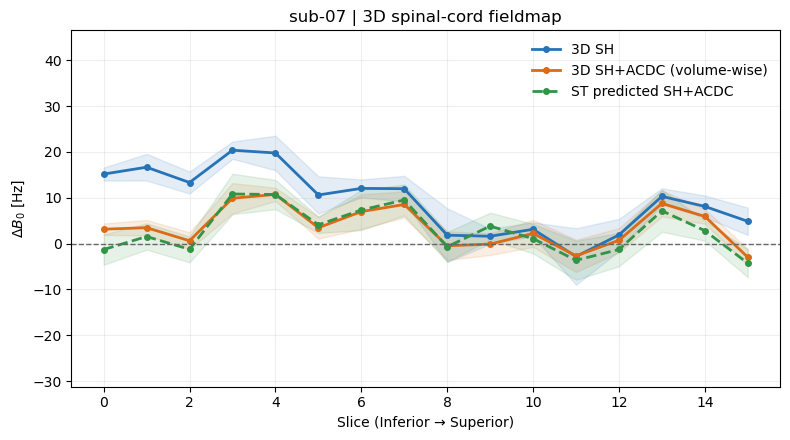

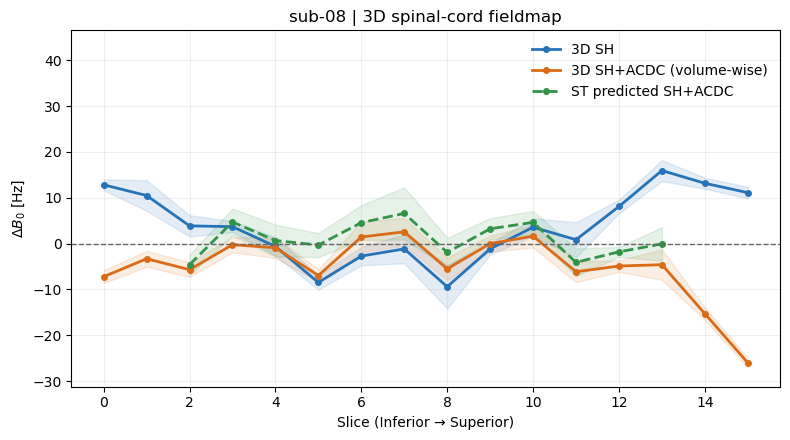

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

styles = {
    "sh": {
        "label": "3D SH",
        "color": "#2673b8",
        "linestyle": "-",
    },
    "sh_acdc": {
        "label": "3D SH+ACDC (volume-wise)",
        "color": "#db6b16",
        "linestyle": "-",
    },
    "predicted_sh_acdc": {
        "label": "ST predicted SH+ACDC",
        "color": "#329447",
        "linestyle": "--",
    },
}

slice_col = "Slice (I->S)"
std_col = "STD()"

data_3d = {}
extents = []

for participant_id, conditions in participants.items():
    data_3d[participant_id] = {}

    for condition in styles:
        csv_path = conditions.get(condition, {}).get("b0_csv_path", "")

        if not csv_path or not Path(csv_path).is_file():
            raise FileNotFoundError(
                f"{participant_id}, {condition}: {csv_path!r}"
            )

        frame = pd.read_csv(csv_path)

        mean_col = next(
            (column for column in ("BIN()", "WA()") if column in frame),
            None,
        )

        if mean_col is None:
            raise ValueError(
                f"{participant_id}, {condition}: missing BIN()/WA()"
            )

        required = [slice_col, mean_col, std_col]
        missing = [column for column in required if column not in frame]

        if missing:
            raise ValueError(
                f"{participant_id}, {condition}: missing columns {missing}"
            )

        frame = (
            frame[required]
            .rename(columns={
                slice_col: "Slice",
                mean_col: "Mean",
                std_col: "SD",
            })
            .apply(pd.to_numeric, errors="raise")
            .sort_values("Slice")
            .reset_index(drop=True)
        )

        if frame.empty or not np.isfinite(frame["Slice"]).all():
            raise ValueError(
                f"{participant_id}, {condition}: empty/invalid slice indices"
            )

        if frame["Slice"].duplicated().any() or (frame["SD"] < 0).any():
            raise ValueError(
                f"{participant_id}, {condition}: duplicate slices/negative SD"
            )

        valid = np.isfinite(frame[["Mean", "SD"]]).all(axis=1)

        if not valid.any():
            raise ValueError(
                f"{participant_id}, {condition}: no finite metrics"
            )

        if not valid.all():
            print(
                f"{participant_id}, {condition}: no metrics on slices "
                f"{frame.loc[~valid, 'Slice'].tolist()}; shown as gaps"
            )
            frame.loc[~valid, ["Mean", "SD"]] = np.nan

        data_3d[participant_id][condition] = frame

        extents.extend([
            float((frame["Mean"] - frame["SD"]).min()),
            float((frame["Mean"] + frame["SD"]).max()),
        ])

# Use the same vertical scale across all participants and conditions.
low = min(0.0, min(extents))
high = max(0.0, max(extents))
padding = max(1.0, 0.06 * (high - low))

figures_3d = {}

for participant_id, conditions in data_3d.items():
    fig, ax = plt.subplots(figsize=(8, 4.5))

    for condition, style in styles.items():
        frame = conditions[condition]

        x = frame["Slice"].to_numpy()
        mean = frame["Mean"].to_numpy()
        sd = frame["SD"].to_numpy()

        ax.plot(
            x,
            mean,
            color=style["color"],
            linestyle=style["linestyle"],
            marker="o",
            markersize=4,
            linewidth=2,
            label=style["label"],
        )

        ax.fill_between(
            x,
            mean - sd,
            mean + sd,
            color=style["color"],
            alpha=0.12,
        )

    ax.axhline(0, color="0.4", linestyle="--", linewidth=1)

    ax.set(
        title=f"{participant_id} | 3D spinal-cord fieldmap",
        xlabel="Slice (Inferior → Superior)",
        ylabel=r"$\Delta B_0$ [Hz]",
        ylim=(low - padding, high + padding),
    )

    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    fig.tight_layout()

    figures_3d[participant_id] = fig
    plt.show()

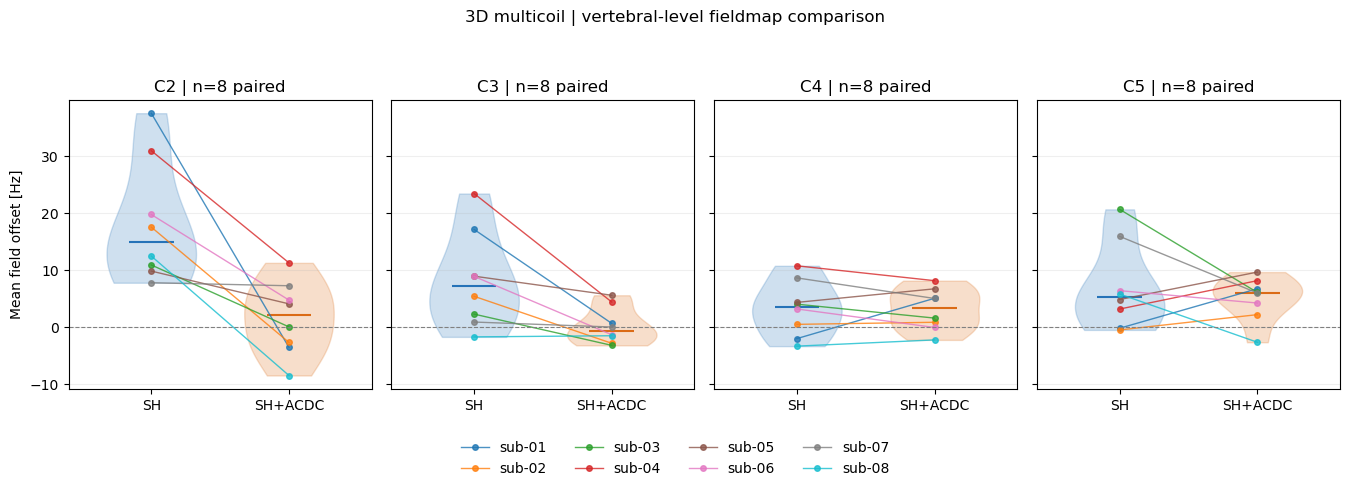

,Participant,Condition,VertLevel,Nvox,Mean,SD,RMSE
0,sub-01,sh,2,688,37.562,3.252,37.702
1,sub-01,sh,3,1035,17.179,5.664,18.089
2,sub-01,sh,4,1488,-1.965,5.579,5.915
3,sub-01,sh,5,758,-0.146,1.555,1.562
4,sub-01,sh_acdc,2,691,-3.508,2.664,4.405
...,...,...,...,...,...,...,...
59,sub-08,sh,5,1273,5.850,3.923,7.043
60,sub-08,sh_acdc,2,1078,-8.436,5.492,10.066
61,sub-08,sh_acdc,3,1080,-1.462,3.990,4.249
62,sub-08,sh_acdc,4,1582,-2.194,4.946,5.411


In [12]:
LEVELS = list(range(2, 6))  # C2–C5 inclusive; edit for your intended coverage.
CONDITIONS = {"sh": ("SH", "#2673b8"),
              "sh_acdc": ("SH+ACDC", "#db6b16")}
METRIC = "Mean"  # "Mean": signed offset; "SD": spatial spread; "RMSE": error to zero.

rows = []
missing_levels = []
for participant_id, conditions in participants.items():
    for condition in CONDITIONS:
        paths = conditions[condition]
        required = ("b0_path", "sc_mask_path", "vert_levels_path")
        for key in required:
            if not paths.get(key) or not Path(paths[key]).is_file():
                raise FileNotFoundError(f"{participant_id}, {condition}, {key}: {paths.get(key)!r}")
        field_img, mask_img, level_img = [nib.load(paths[k]) for k in required]
        if len(field_img.shape) != 3:
            raise ValueError(f"{participant_id}, {condition}: expected a 3D fieldmap")
        for image in (mask_img, level_img):
            if (image.shape != field_img.shape
                    or not np.allclose(image.affine, field_img.affine, atol=1e-4, rtol=0)):
                raise ValueError(f"{participant_id}, {condition}: image/mask/labels grids differ; check alignment")
        field, mask, labels = [image.get_fdata() for image in (field_img, mask_img, level_img)]
        finite_labels = labels[np.isfinite(labels)]
        if not np.allclose(finite_labels, np.rint(finite_labels), atol=1e-5, rtol=0):
            raise ValueError(f"{participant_id}, {condition}: vertebral labels must be discrete integers")
        # Binary ROI policy: include finite, positive SC-mask voxels.
        valid = np.isfinite(field) & np.isfinite(mask) & (mask > 0)
        for level in LEVELS:
            values = field[valid & (labels == level)]
            if not values.size:
                missing_levels.append((participant_id, condition, level))
                continue
            rows.append({"Participant": participant_id, "Condition": condition,
                         "VertLevel": level, "Nvox": values.size,
                         "Mean": values.mean(), "SD": values.std(ddof=0),
                         "RMSE": np.sqrt(np.mean(values**2))})

vertebral_fieldmap_df = pd.DataFrame(rows)
if vertebral_fieldmap_df.empty:
    raise ValueError("No usable voxels in the selected levels")

# Use complete SH/SH+ACDC pairs separately at each level.
paired_levels = {}
for level in LEVELS:
    paired = (vertebral_fieldmap_df.query("VertLevel == @level")
              .pivot(index="Participant", columns="Condition", values=METRIC)
              .reindex(columns=list(CONDITIONS)).dropna())
    paired_levels[level] = paired

fig, axes = plt.subplots(1, len(LEVELS), figsize=(3.4 * len(LEVELS), 4.8),
                         sharey=True, squeeze=False)
subject_colors = dict(zip(sorted(participants),
                          plt.get_cmap("tab10")(np.linspace(0, 0.9, len(participants)))))
for ax, level in zip(axes.ravel(), LEVELS):
    paired = paired_levels[level]
    for position, (condition, (label, color)) in enumerate(CONDITIONS.items()):
        values = paired[condition].to_numpy()
        # KDE requires at least two distinct values. Points are always retained.
        if len(values) >= 2 and np.ptp(values) > 1e-10:
            parts = ax.violinplot(values, positions=[position], widths=0.65,
                                  showmeans=False, showmedians=True, showextrema=False)
            for body in parts["bodies"]:
                body.set_facecolor(color)
                body.set_edgecolor(color)
                body.set_alpha(0.22)
            parts["cmedians"].set_color(color)
    for participant_id, row in paired.iterrows():
        ax.plot([0, 1], row[list(CONDITIONS)].to_numpy(), "o-",
                color=subject_colors[participant_id], alpha=0.8,
                linewidth=1, markersize=4, label=participant_id)
    ax.axhline(0, color="0.5", linestyle="--", linewidth=0.8)
    ax.set_xticks([0, 1], [value[0] for value in CONDITIONS.values()])
    ax.set_xlim(-0.6, 1.6)
    # Level codes 2–7 = C2–C7; codes 8 onward are thoracic levels.
    level_name = f"C{level}" if level <= 7 else f"T{level-7}"
    ax.set_title(f"{level_name} | n={len(paired)} paired")
    ax.grid(axis="y", alpha=0.2)
    if paired.empty:
        ax.text(0.5, 0.5, "No complete pairs", transform=ax.transAxes, ha="center")

ylabels = {"Mean": "Mean field offset [Hz]", "SD": "Spatial field SD [Hz]",
           "RMSE": "Field RMSE relative to zero [Hz]"}
axes[0, 0].set_ylabel(ylabels[METRIC])
handles = {}
for ax in axes.ravel():
    h, labels = ax.get_legend_handles_labels()
    handles.update(zip(labels, h))
if handles:
    fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=4, frameon=False)
fig.suptitle("3D multicoil | vertebral-level fieldmap comparison", y=0.99)
fig.tight_layout(rect=[0, 0.12, 1, 0.94])
plt.show()
display(vertebral_fieldmap_df.round(3))
if missing_levels:
    print("No valid SC voxels for (participant, condition, level):", missing_levels)

# Each dot = one participant's metric across SC voxels within that exact vertebral label.
# Each violin = distribution of participant metrics, not pooled voxels.
# Finite zeros are included. Restrict valid further if reconstruction support requires it.

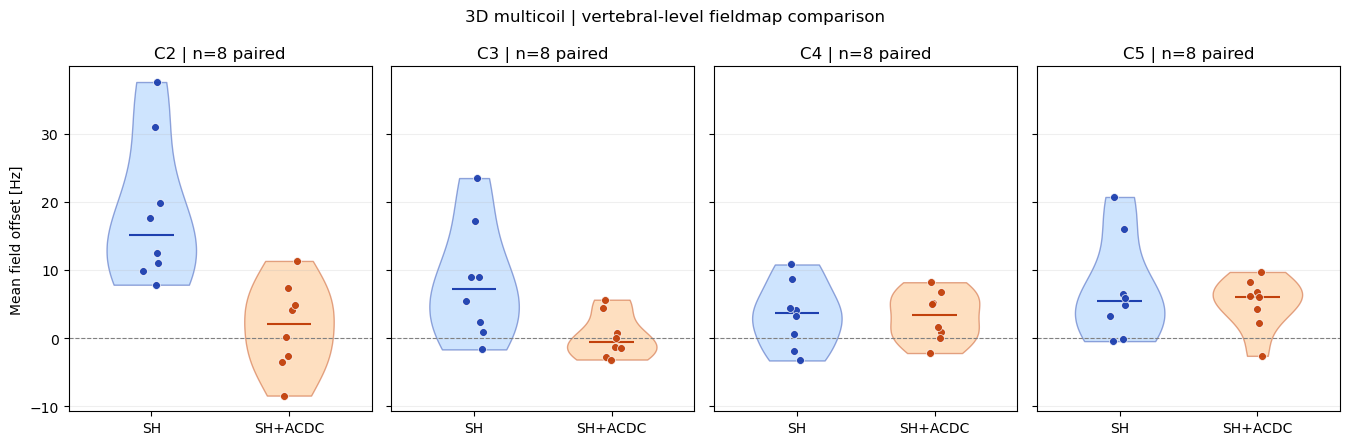

In [18]:
import numpy as np
import matplotlib.pyplot as plt

LEVELS = list(range(2, 6))  # C2–C5
METRIC = "Mean"            # "Mean", "SD", or "RMSE"

styles = {
    "sh": ("SH", "#93c5fd", "#1e40af"),
    "sh_acdc": ("SH+ACDC", "#fdba74", "#c2410c"),
}

fig, axes = plt.subplots(
    1, len(LEVELS),
    figsize=(3.4 * len(LEVELS), 4.5),
    sharey=True,
    squeeze=False,
)

rng = np.random.default_rng(42)

for ax, level in zip(axes.ravel(), LEVELS):

    # Retain participants with both conditions at this level.
    paired = (
        vertebral_fieldmap_df
        .loc[lambda df: df["VertLevel"] == level]
        .pivot(
            index="Participant",
            columns="Condition",
            values=METRIC,
        )
        .reindex(columns=list(styles))
        .dropna()
    )

    for position, (condition, (label, fill_color, dot_color)) in enumerate(styles.items()):
        values = paired[condition].to_numpy()

        if len(values) >= 2 and np.ptp(values) > 1e-10:
            parts = ax.violinplot(
                values,
                positions=[position],
                widths=0.65,
                showmeans=False,
                showmedians=True,
                showextrema=False,
            )

            for body in parts["bodies"]:
                body.set_facecolor(fill_color)
                body.set_edgecolor(dot_color)
                body.set_alpha(0.45)

            parts["cmedians"].set_color(dot_color)

        jitter = rng.uniform(-0.07, 0.07, size=len(values))

        ax.scatter(
            position + jitter,
            values,
            color=dot_color,
            edgecolors="white",
            linewidths=0.5,
            s=32,
            alpha=0.95,
            zorder=3,
        )

    level_name = f"C{level}" if level <= 7 else f"T{level - 7}"

    ax.axhline(0, color="0.5", linestyle="--", linewidth=0.8)
    ax.set_title(f"{level_name} | n={len(paired)} paired")
    ax.set_xticks([0, 1], [style[0] for style in styles.values()])
    ax.set_xlim(-0.6, 1.6)
    ax.grid(axis="y", alpha=0.2)

ylabels = {
    "Mean": "Mean field offset [Hz]",
    "SD": "Spatial field SD [Hz]",
    "RMSE": "Field RMSE relative to zero [Hz]",
}

axes[0, 0].set_ylabel(ylabels[METRIC])
fig.suptitle("3D multicoil | vertebral-level fieldmap comparison")
fig.tight_layout()
plt.show()

In [ ]:
# P-tests for the 8 points at each vertebral level:


###  <span style="color:#12B06C"> Figure 2 panel MSE </span> 

In [19]:
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

target_b0 = 0.0  # Hz
results = []

for participant_id, conditions in participants.items():

    condition_metrics = {}

    for condition in ("sh", "sh_acdc"):
        paths = conditions[condition]

        field_img = nib.load(paths["b0_path"])
        mask_img = nib.load(paths["sc_mask_path"])

        # Confirm that the fieldmap and mask share the same grid.
        if (
            field_img.shape != mask_img.shape
            or not np.allclose(
                field_img.affine,
                mask_img.affine,
                atol=1e-4,
                rtol=0,
            )
        ):
            raise ValueError(
                f"{participant_id}, {condition}: fieldmap/mask grids differ"
            )

        field = field_img.get_fdata()
        mask = mask_img.get_fdata()

        roi = (
            np.isfinite(field)
            & np.isfinite(mask)
            & (mask > 0)
        )

        values = field[roi]

        if values.size == 0:
            raise ValueError(
                f"{participant_id}, {condition}: no valid SC voxels"
            )

        condition_metrics[condition] = {
            "MSE": np.mean((values - target_b0) ** 2),
            "Nvox": values.size,
        }

    sh_mse = condition_metrics["sh"]["MSE"]
    sh_acdc_mse = condition_metrics["sh_acdc"]["MSE"]

    reduction = (
        100 * (sh_mse - sh_acdc_mse) / sh_mse
        if sh_mse > 0 else np.nan
    )

    results.append({
        "Participant": participant_id,
        "SH MSE": sh_mse,
        "SH+ACDC MSE": sh_acdc_mse,
        "MSE Reduction (%)": reduction,
        "SH Nvox": condition_metrics["sh"]["Nvox"],
        "SH+ACDC Nvox": condition_metrics["sh_acdc"]["Nvox"],
    })

mse_df = (
    pd.DataFrame(results)
    .sort_values("Participant")
    .reset_index(drop=True)
)

display(mse_df.round(3))

,Participant,SH MSE,SH+ACDC MSE,MSE Reduction (%),SH Nvox,SH+ACDC Nvox
0,sub-01,278.446,40.552,85.436,5816,5236
1,sub-02,113.063,58.507,48.252,5731,5681
2,sub-03,214.470,35.347,83.519,5865,5871
3,sub-04,330.117,80.740,75.542,5878,5500
4,sub-05,70.326,83.073,-18.126,5807,6076
5,sub-06,154.667,34.673,77.582,6522,6603
6,sub-07,144.488,38.399,73.424,5861,5978
7,sub-08,73.415,78.076,-6.348,6090,6229


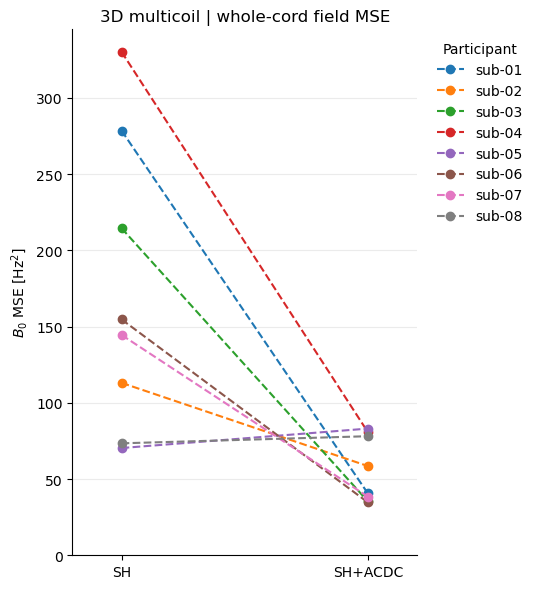

In [20]:
fig, ax = plt.subplots(figsize=(5.5, 6))

x = [0, 1]
colors = plt.get_cmap("tab10").colors

for index, (_, row) in enumerate(mse_df.iterrows()):

    ax.plot(
        x,
        [row["SH MSE"], row["SH+ACDC MSE"]],
        color=colors[index % len(colors)],
        marker="o",
        linestyle="--",
        linewidth=1.5,
        markersize=6,
        label=row["Participant"],
    )

ax.set_xticks(x, ["SH", "SH+ACDC"])
ax.set_xlim(-0.2, 1.2)
ax.set_ylim(bottom=0)

ax.set_ylabel(r"$B_0$ MSE [Hz$^2$]")
ax.set_title("3D multicoil | whole-cord field MSE")

ax.legend(
    title="Participant",
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

##  <span style="color:#7327F5"> Magnitude analysis


In [21]:
# ============================================================
# Magnitude tissue statistics — SH vs SH+ACDC
# ============================================================

import numpy as np
import pandas as pd
import nibabel as nib

condition_labels = {
    "sh": "SH",
    "sh_acdc": "SH+ACDC",
}

magnitude_results = []

for participant_id, conditions in participants.items():

    for condition, label in condition_labels.items():
        paths = conditions[condition]

        mag_img = nib.load(paths["magnitude_path"])
        mag = mag_img.get_fdata()

        row = {
            "Participant": participant_id,
            "Condition": label,
        }

        for tissue, mask_key in (
            ("GM", "gm_mask_path"),
            ("WM", "wm_mask_path"),
        ):
            mask_img = nib.load(paths[mask_key])

            # Confirm matching image grids.
            if (
                mag_img.shape != mask_img.shape
                or not np.allclose(
                    mag_img.affine,
                    mask_img.affine,
                    atol=1e-4,
                    rtol=0,
                )
            ):
                raise ValueError(
                    f"{participant_id}, {label}, {tissue}: "
                    "magnitude/mask grids differ"
                )

            mask = mask_img.get_fdata()

            roi = (
                np.isfinite(mag)
                & np.isfinite(mask)
                & (mask > 0)
            )

            values = mag[roi]

            if values.size == 0:
                raise ValueError(
                    f"{participant_id}, {label}, {tissue}: "
                    "no valid tissue voxels"
                )

            mean = values.mean()
            sd = values.std(ddof=0)
            cv = sd / mean if mean > 0 else np.nan

            row.update({
                f"{tissue} Mean": mean,
                f"{tissue} SD": sd,
                f"{tissue} CV": cv,
                f"{tissue} CV (%)": 100 * cv,
                f"{tissue} Nvox": values.size,
            })

        magnitude_results.append(row)

magnitude_metrics_df = pd.DataFrame(magnitude_results)

display(magnitude_metrics_df.round(3))

,Participant,Condition,GM Mean,GM SD,GM CV,GM CV (%),GM Nvox,WM Mean,WM SD,WM CV,WM CV (%),WM Nvox
0,sub-01,SH,59.942,10.753,0.179,17.940,1060,52.955,10.677,0.202,20.162,5642
1,sub-01,SH+ACDC,61.836,6.559,0.106,10.607,803,56.852,6.944,0.122,12.215,4436
2,sub-02,SH,65.124,11.250,0.173,17.275,972,59.383,10.523,0.177,17.720,4762
3,sub-02,SH+ACDC,60.846,9.483,0.156,15.586,910,55.181,10.465,0.190,18.966,4771
4,sub-03,SH,53.446,5.205,0.097,9.738,1078,46.759,6.083,0.130,13.008,4789
5,sub-03,SH+ACDC,52.419,5.271,0.101,10.055,1012,46.360,6.647,0.143,14.337,4859
6,sub-04,SH,57.959,10.207,0.176,17.612,1029,51.008,10.545,0.207,20.673,4850
7,sub-04,SH+ACDC,59.438,8.399,0.141,14.130,1016,51.934,9.223,0.178,17.759,4503
8,sub-05,SH,74.102,10.366,0.140,13.988,1069,65.809,11.743,0.178,17.844,4739
9,sub-05,SH+ACDC,64.344,10.815,0.168,16.808,1038,57.302,11.136,0.194,19.433,5040


In [22]:
cv_comparison_df = (
    magnitude_metrics_df
    .pivot(
        index="Participant",
        columns="Condition",
        values=["GM CV (%)", "WM CV (%)"],
    )
    .reindex(
        columns=pd.MultiIndex.from_product([
            ["GM CV (%)", "WM CV (%)"],
            ["SH", "SH+ACDC"],
        ])
    )
)

display(cv_comparison_df.round(2))

GM CV (%)         WM CV (%)        
                   SH SH+ACDC        SH SH+ACDC
Participant                                    
sub-01          17.94   10.61     20.16   12.21
sub-02          17.28   15.59     17.72   18.97
sub-03           9.74   10.06     13.01   14.34
sub-04          17.61   14.13     20.67   17.76
sub-05          13.99   16.81     17.84   19.43
sub-06          10.73   15.78     15.60   19.21
sub-07          14.79   15.05     18.24   17.73
sub-08          12.07   10.90     13.27   12.11

##  <span style="color:#7327F5"> Figure 4 - Dipole inversion results only 3D 

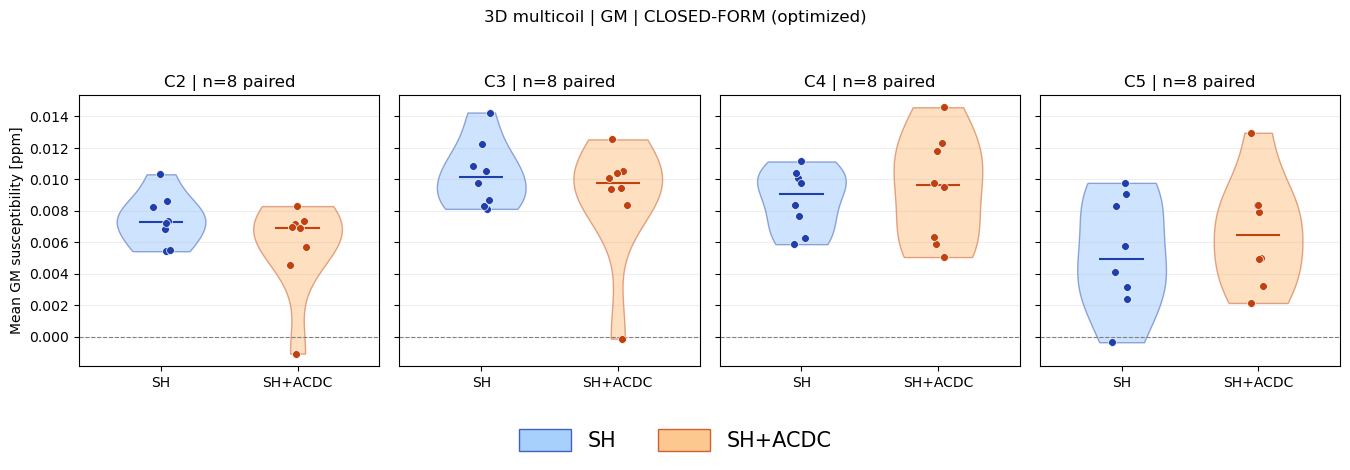

In [23]:
# GM cell: defines the shared plotting function, then plots GM.
# Run after: participants = data_paths.participants
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


def plot_di_means(participants, tissue, method="closedform", levels=(2, 3, 4, 5),
                  show_legend=True, units="ppm"):
    """Plot paired participant means using binary tissue-mask/level intersections."""
    methods = {"closedform": ("chimap_closedform_path", "CLOSED-FORM"),
               "medi": ("chimap_medi_path", "MEDI"),
               "fansi": ("chimap_fansi_path", "FANSI")}
    if method not in methods or tissue not in ("GM", "WM"):
        raise ValueError("Use method='closedform', 'medi', or 'fansi'; tissue='GM' or 'WM'.")
    if not levels:
        raise ValueError("Select at least one vertebral level.")
    map_key, method_label = methods[method]
    styles = {"sh": ("SH", "#93c5fd", "#1e40af"),
              "sh_acdc": ("SH+ACDC", "#fdba74", "#c2410c")}
    rows = []
    missing = []
    for participant_id, conditions in participants.items():
        for condition in styles:
            paths = conditions[condition]
            keys = (map_key, f"{tissue.lower()}_mask_path", "sc_mask_path", "vert_levels_path")
            for key in keys:
                if not paths.get(key) or not Path(paths[key]).is_file():
                    raise FileNotFoundError(f"{participant_id}, {condition}, {key}: {paths.get(key)!r}")
            images = [nib.load(paths[key]) for key in keys]
            reference = images[0]
            if len(reference.shape) != 3 or any(
                img.shape != reference.shape or not np.allclose(
                    img.affine, reference.affine, atol=1e-4, rtol=0)
                for img in images[1:]
            ):
                raise ValueError(f"{participant_id}, {condition}: map/masks/labels must share a 3D grid.")
            chi, mask, sc, labels = [img.get_fdata() for img in images]
            finite_labels = labels[np.isfinite(labels)]
            if not np.allclose(finite_labels, np.rint(finite_labels), atol=1e-5, rtol=0):
                raise ValueError(f"{participant_id}, {condition}: use discrete vertebral labels.")
            valid = (np.isfinite(chi) & np.isfinite(mask) & (mask > 0)
                     & np.isfinite(sc) & (sc > 0))
            for level in levels:
                values = chi[valid & (labels == level)]
                if not values.size:
                    missing.append((participant_id, condition, level))
                    continue
                rows.append({"Participant": participant_id, "Condition": condition,
                             "VertLevel": level, "Tissue": tissue, "Method": method_label,
                             "Mean": values.mean(), "SD": values.std(ddof=0), "Nvox": values.size})
    if not rows:
        raise ValueError("No valid tissue voxels in the selected levels.")
    metrics_df = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, len(levels), figsize=(3.4 * len(levels), 4.7),
                             sharey=True, squeeze=False)
    rng = np.random.default_rng(42)
    for ax, level in zip(axes.ravel(), levels):
        paired = (metrics_df.loc[metrics_df.VertLevel == level]
                  .pivot(index="Participant", columns="Condition", values="Mean")
                  .reindex(columns=list(styles)).dropna())
        for position, (condition, (label, fill, dark)) in enumerate(styles.items()):
            values = paired[condition].to_numpy()
            if len(values) >= 2 and np.ptp(values) > 1e-12:
                parts = ax.violinplot(values, positions=[position], widths=0.65,
                                      showmeans=False, showmedians=True, showextrema=False)
                for body in parts["bodies"]:
                    body.set_facecolor(fill)
                    body.set_edgecolor(dark)
                    body.set_alpha(0.45)
                parts["cmedians"].set_color(dark)
            ax.scatter(position + rng.uniform(-0.07, 0.07, len(values)), values,
                       color=dark, edgecolors="white", linewidths=0.5, s=32, zorder=3)
        level_label = f"C{level}" if level <= 7 else f"T{level - 7}"
        ax.set_title(f"{level_label} | n={len(paired)} paired")
        ax.set_xticks([0, 1], [style[0] for style in styles.values()])
        ax.set_xlim(-0.6, 1.6)
        ax.axhline(0, color="0.5", linestyle="--", linewidth=0.8)
        ax.grid(axis="y", alpha=0.2)
        if paired.empty:
            ax.text(0.5, 0.5, "No complete pairs", ha="center", transform=ax.transAxes)
    axes[0, 0].set_ylabel(f"Mean {tissue} susceptibility [{units}]")
    fig.suptitle(f"3D multicoil | {tissue} | {method_label} (optimized)")
    if show_legend:
        handles = [Patch(facecolor=fill, edgecolor=dark, label=label, alpha=0.8)
                   for label, fill, dark in styles.values()]
        fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False,
                   fontsize=15, handlelength=2.5, handleheight=1.3)
    fig.tight_layout(rect=[0, 0.14 if show_legend else 0, 1, 0.94])
    plt.show()
    if missing:
        print("No tissue voxels for (participant, condition, level):", missing)
    return metrics_df, fig


# GM settings: edit these and rerun this cell.
GM_METHOD = "closedform"  # "closedform", "medi", or "fansi"
GM_SHOW_LEGEND = True
GM_LEVELS = (2, 3, 4, 5)

gm_di_metrics_df, gm_di_fig = plot_di_means(
    participants, tissue="GM", method=GM_METHOD,
    levels=GM_LEVELS, show_legend=GM_SHOW_LEGEND,
)


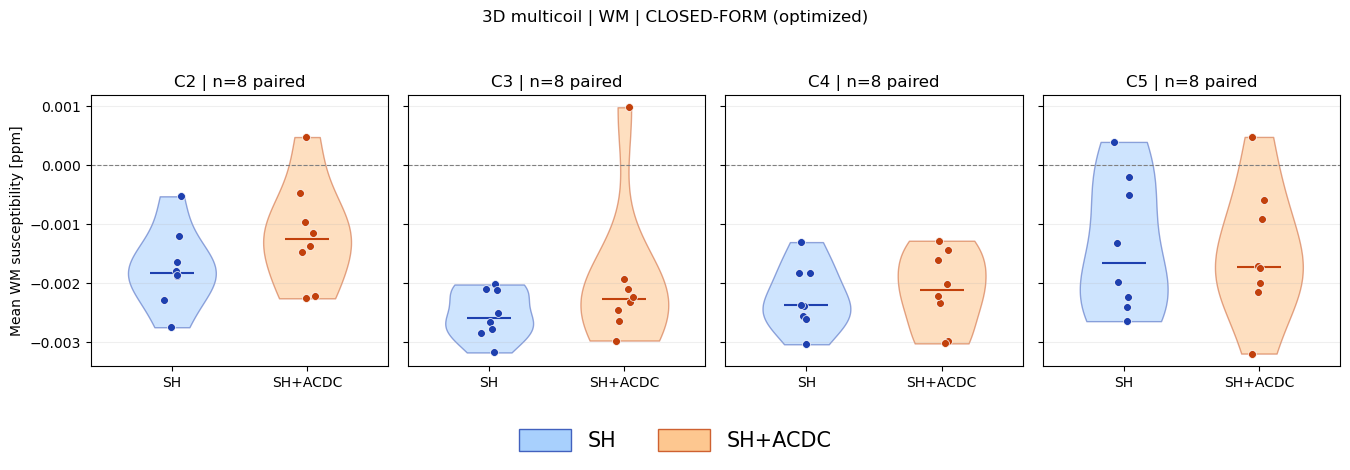

In [25]:
# WM cell: run after the GM cell, which defines plot_di_means.
WM_METHOD = "closedform"  # "closedform", "medi", or "fansi"
WM_SHOW_LEGEND = True
WM_LEVELS = (2, 3, 4, 5)

wm_di_metrics_df, wm_di_fig = plot_di_means(
    participants, tissue="WM", method=WM_METHOD,
    levels=WM_LEVELS, show_legend=WM_SHOW_LEGEND,
)


In [26]:
di_check_df = pd.concat([
    gm_di_metrics_df.assign(Tissue="GM"),
    wm_di_metrics_df.assign(Tissue="WM"),
], ignore_index=True)

display(
    di_check_df
    .loc[lambda df: df["VertLevel"].isin([2, 3])]
    .sort_values(["Participant", "Tissue", "VertLevel", "Condition"])
    .round(6)
)

,Participant,Condition,VertLevel,Tissue,Method,Mean,SD,Nvox
0,sub-01,sh,2,GM,CLOSED-FORM,0.005427,0.007380,125
4,sub-01,sh_acdc,2,GM,CLOSED-FORM,0.004571,0.005844,113
1,sub-01,sh,3,GM,CLOSED-FORM,0.012258,0.008188,176
5,sub-01,sh_acdc,3,GM,CLOSED-FORM,0.010528,0.010130,226
64,sub-01,sh,2,WM,CLOSED-FORM,-0.001882,0.006081,548
...,...,...,...,...,...,...,...,...
61,sub-08,sh_acdc,3,GM,CLOSED-FORM,0.008382,0.006185,188
120,sub-08,sh,2,WM,CLOSED-FORM,-0.001859,0.004996,859
124,sub-08,sh_acdc,2,WM,CLOSED-FORM,-0.001475,0.004315,898
121,sub-08,sh,3,WM,CLOSED-FORM,-0.002109,0.005954,1204


In [28]:
# Paired tests on participant-level spatial SDs (or means).
# Run after creating gm_di_metrics_df and wm_di_metrics_df.
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel
from IPython.display import display

METRIC = "SD"  # "SD" = within-tissue spatial SD; "Mean" = tissue mean susceptibility.
LEVELS = (2, 3, 4, 5)
rows = []

for tissue, frame in {"GM": gm_di_metrics_df, "WM": wm_di_metrics_df}.items():
    frame = frame.loc[frame.Condition.isin(["sh", "sh_acdc"])].copy()
    if frame.duplicated(["Participant", "VertLevel", "Condition"]).any():
        raise ValueError(f"{tissue}: select only one DI method/acquisition per participant.")
    for level in LEVELS:
        paired = (
            frame.loc[frame.VertLevel == level]
            .pivot(index="Participant", columns="Condition", values=METRIC)
            .reindex(columns=["sh", "sh_acdc"])
            .replace([np.inf, -np.inf], np.nan).dropna()
        )
        before = paired["sh"].to_numpy(dtype=float)
        after = paired["sh_acdc"].to_numpy(dtype=float)
        delta = after - before
        p = low = high = np.nan
        if len(paired) >= 2:
            if np.all(delta == 0):
                p, low, high = 1.0, 0.0, 0.0
            else:
                test = ttest_rel(after, before, alternative="two-sided")
                ci = test.confidence_interval(confidence_level=0.95)
                p, low, high = test.pvalue, ci.low, ci.high
        rows.append({
            "Tissue": tissue, "Metric": METRIC,
            "Method": frame["Method"].iloc[0] if "Method" in frame and not frame.empty else "",
            "VertLevel": level, "N paired": len(paired),
            "SH average": before.mean() if len(paired) else np.nan,
            "SH+ACDC average": after.mean() if len(paired) else np.nan,
            "Difference (ACDC-SH)": delta.mean() if len(paired) else np.nan,
            "Difference CI95 low": low, "Difference CI95 high": high,
            "p raw (two-sided)": p,
        })

di_paired_ttests_df = pd.DataFrame(rows)
display(di_paired_ttests_df.round(6))
# Negative SD differences indicate lower within-tissue spatial variability.
# Raw exploratory p-values; no multiple-comparison adjustment is applied here.
# Assumption: independent participants and approximately normal paired differences.


,Tissue,Metric,Method,VertLevel,N paired,SH average,SH+ACDC average,Difference (ACDC-SH),Difference CI95 low,Difference CI95 high,p raw (two-sided)
0,GM,SD,CLOSED-FORM,2,8,0.007512,0.006978,-0.000534,-0.002844,0.001776,0.601564
1,GM,SD,CLOSED-FORM,3,8,0.008217,0.008702,0.000485,-0.001725,0.002694,0.619907
2,GM,SD,CLOSED-FORM,4,8,0.008127,0.007893,-0.000234,-0.001500,0.001032,0.675362
3,GM,SD,CLOSED-FORM,5,8,0.008193,0.007691,-0.000501,-0.001826,0.000823,0.400297
4,WM,SD,CLOSED-FORM,2,8,0.006148,0.005426,-0.000722,-0.002538,0.001094,0.378491
5,WM,SD,CLOSED-FORM,3,8,0.007947,0.008634,0.000686,-0.001426,0.002798,0.467561
6,WM,SD,CLOSED-FORM,4,8,0.009223,0.009223,0.000001,-0.001806,0.001807,0.999486
7,WM,SD,CLOSED-FORM,5,8,0.008888,0.007788,-0.001101,-0.002787,0.000585,0.166542
